In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
halogen_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import violin
from edautils.plot import pie
from edautils.plot import plot

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

os.chdir(halogen_dir)

In [2]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

plt.rcParams.update({
    # 'font.size': 12,
    # 'axes.titlesize': 12,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Lato'],
})

COLOR_MAPS = {
    "TOTAL": '#666666',
    "CT": '#b80058',
    "DISP": "#d95f02",
    "ELEC": '#5954d6',
    "POL": '#1b9e77',
    "PAULI": '#ebac23',
    'FRZ': '#a6cee3'
}

df = pd.read_csv('halogen_EDA.csv').iloc[:, 1:]
print('# Total pairs:', len(df))
print('# Repulsive pairs:', len(df.query('TOTAL > 0')))
print('# Attractive pairs:', len(df.query('TOTAL < 0')))

# CLS_DISP
df['DISP'] = np.where(np.isnan(df['DISP'].values), df['CLS_DISP'], df['DISP'])
processed_df = df.query('TOTAL < 0').drop(columns=['resnr_lig', 'restype_lig', 'reschain_lig', 'PREPARATION'])

for x, subdf in processed_df.groupby("donortype"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())


components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

include_all = False
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in ['F', 'Cl', 'Br', 'I']:
        data = processed_df.query(f'donortype == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

# Total pairs: 1318
# Repulsive pairs: 254
# Attractive pairs: 1064
Br 110 -57.908
Cl 501 -209.93
F 376 -80.8458
I 77 -34.2255
Total & $-5.95\ (-3.12)$ & $-5.80\ (-4.74)$ & $-10.01\ (-8.15)$ & $-12.72\ (-12.40)$ \\
Pauli & $7.85\ (4.79)$ & $9.83\ (7.22)$ & $13.56\ (11.12)$ & $19.80\ (12.64)$ \\
Electrostatics & $-3.03\ (-0.17)$ & $-3.63\ (-2.18)$ & $-8.09\ (-6.42)$ & $-13.09\ (-9.92)$ \\
Dispersion & $-7.76\ (-6.86)$ & $-8.75\ (-8.05)$ & $-9.79\ (-9.52)$ & $-12.65\ (-11.55)$ \\
Polarization & $-1.92\ (-0.72)$ & $-1.86\ (-1.18)$ & $-3.59\ (-2.25)$ & $-3.78\ (-2.75)$ \\
Charge Transfer & $-1.10\ (-0.65)$ & $-1.39\ (-1.03)$ & $-2.10\ (-1.73)$ & $-2.99\ (-1.94)$ \\


# Violin + Bar Plots

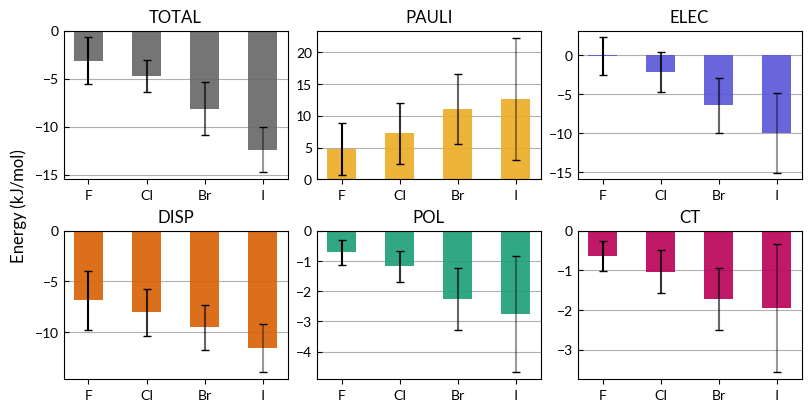

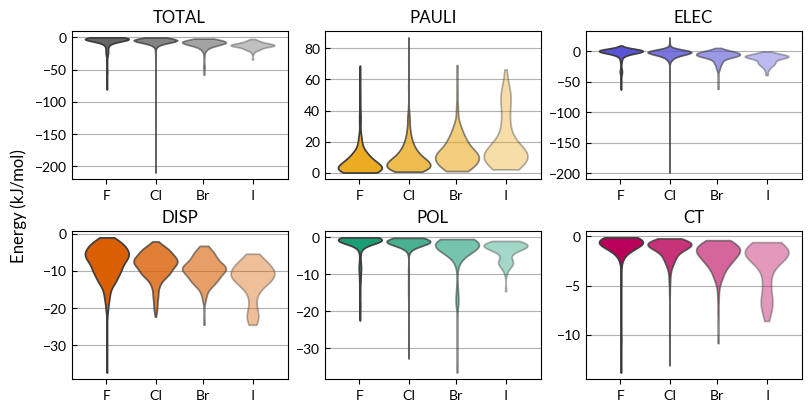

In [4]:
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'donortype'
groups = ['F', 'Cl', 'Br', 'I']
labels = ['F', 'Cl', 'Br', 'I']

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin.png')

# Pie Plot

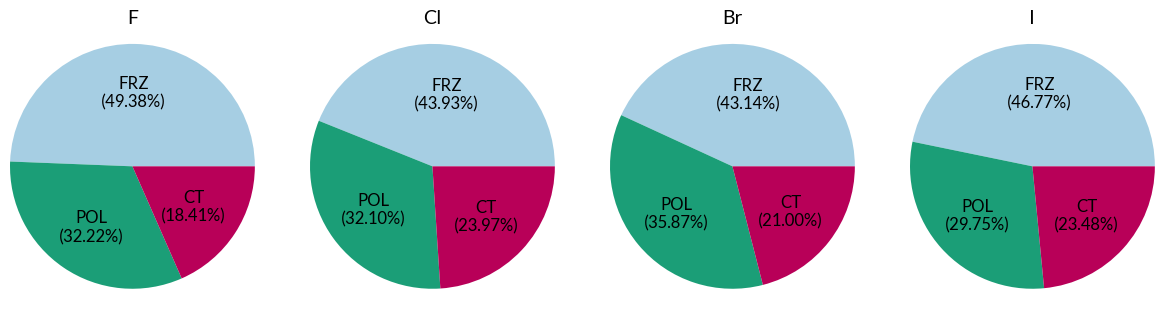

In [5]:
fig, axes = plt.subplots(1, 4, constrained_layout=True, figsize=(12, 3))
pie(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie.png')

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_9210/932190174.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


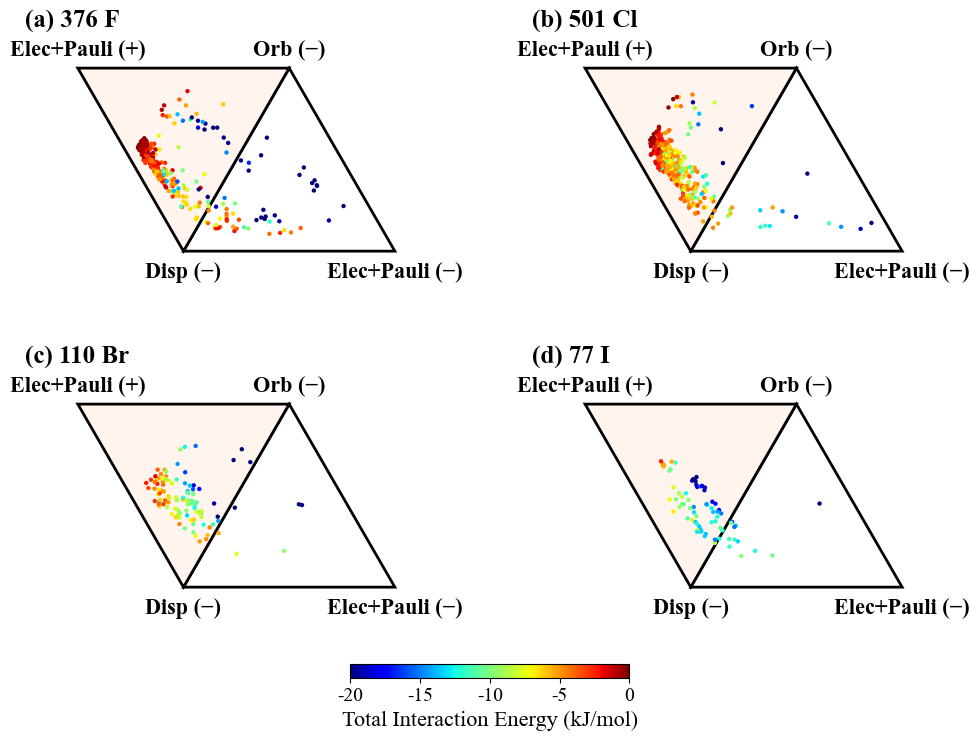

In [17]:
labels = ['F', 'Cl', 'Br', 'I']

def split_halogen(df):
    dfList = []
    dfList.append(df.query('donortype == "F" & TOTAL < 0'))
    dfList.append(df.query('donortype == "Cl" & TOTAL < 0'))
    dfList.append(df.query('donortype == "Br" & TOTAL < 0'))
    dfList.append(df.query('donortype == "I" & TOTAL < 0'))
    return dfList

dfs = split_halogen(df)
labels = ['F', 'Cl', 'Br', 'I']
cmap_range = [-20, 0]
types = 'frz_orb_disp'

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
sc = plot('ternary', (labels[0], 'a', types), dfs[0], axes[0,0], cmap_range)
plot('ternary', (labels[1], 'b', types), dfs[1], axes[0,1], cmap_range)
plot('ternary', (labels[2], 'c', types), dfs[2], axes[1,0], cmap_range)
plot('ternary', (labels[3], 'd', types), dfs[3], axes[1,1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
fig.savefig('Visualizations/ternary.png')

# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

In [22]:
dfs = split_halogen(df)

len(dfs)

4

len: list(map(len, dfs))


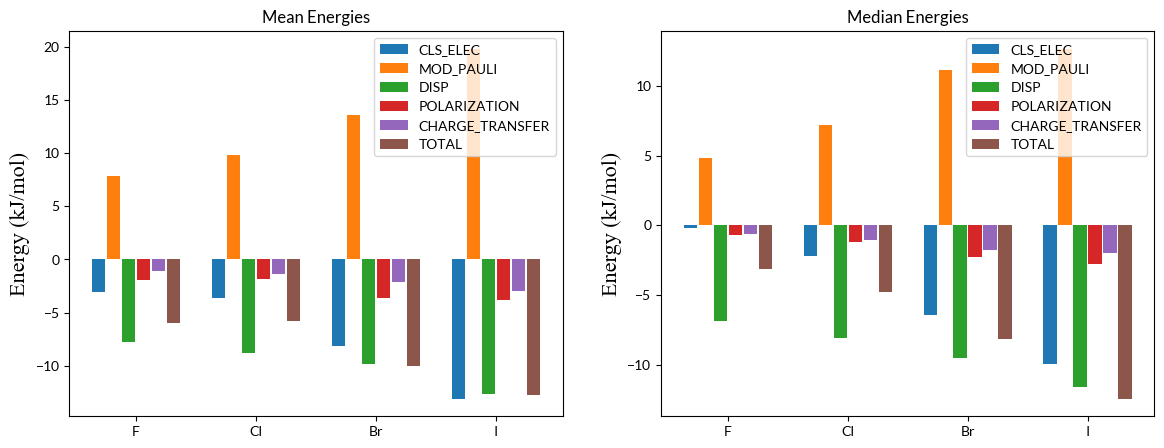

In [28]:
labels = ['F', 'Cl', 'Br', 'I']
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_halogen(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('box', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('box', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/box.png')

# Dist Plot

In [19]:
def split_eda(df):
    dfList = []
    frozen = df.query("TOTAL < 0 & FROZEN < 20 & FROZEN > -20")
    elec = df.query("TOTAL < 0 & CLS_ELEC > -50 & CLS_ELEC < 10")
    pauli = df.query("TOTAL < 0")
    disp = df.query("TOTAL < 0")
    pol = df.query("TOTAL < 0 & POLARIZATION > -10")
    ct = df.query("TOTAL < 0 & CHARGE_TRANSFER > -10")
    total = df.query("TOTAL < 0 & TOTAL > -50")
    return [frozen, elec, pauli, disp, pol, ct, total]

palette = sns.color_palette(n_colors=len(labels))
eda_dfs = split_eda(df)
items = [
    'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

# for index, df in enumerate(eda_dfs):
#     fig, axes = plt.subplots(1, 2, figsize=(14, 5))
#     plot('dist', ('donortype', labels, items[index], palette), df, axes[0])
#     plot('dist', ('donortype', labels, items[index], palette), df, axes[1], kde_norm=True)
#     plt.savefig(f'Visualizations/dist_{items[index]}.png')



# Attatched Ligand Group F and Cl

In [16]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from openbabel import openbabel
from tqdm import tqdm

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
df = pd.read_csv("halogen_EDA.csv", index_col=0)

In [17]:
alkyl = '[CX4:1]([F,Cl,Br,I:2])'
ring = '[c:1]-[F,Cl,Br,I:2]'

patts = [alkyl, ring]
patts = list(map(Chem.MolFromSmarts, patts))

def find_groups(mol, idx):    
    for index, patt in enumerate(patts):
        for sub in mol.GetSubstructMatches(patt):
            if sub[1] == (idx - 1):
                if index == 0:
                    C_idx = sub[0]
                    amount = len([sub for sub in mol.GetSubstructMatches(patt) if sub[0] == C_idx])
                    if amount >= 1:
                        return 'alkyl'
                    # if amount == 1:
                    #     return 'alkyl_1'
                    # elif amount == 2:
                    #     return 'alkyl_2'
                    # elif amount == 3:
                    #     return 'alkyl_3'
                elif index == 1:
                    return 'ring'
    return None

groups = []
groupID = []

for index, row in tqdm(df.iterrows()):
    mol = Chem.SDMolSupplier(os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"), removeHs=False)[0]
    groups.append(find_groups(mol, row['don_idx']))
    groupID.append([row['full_PDBID'], row['subdir'], find_groups(mol, row['don_idx'])])

df['group'] = groups

145it [00:00, 1441.37it/s]


AttributeError: 'NoneType' object has no attribute 'GetSubstructMatches'